# Stock Price Prediction

**Goal:** predict the next-day closing price of a stock (regression) and the next-day direction, up or down (classification), from its price history.

**Dataset:** *S&P 500 stock data* (Kaggle, Cam Nugent): daily open/high/low/close/volume for 505 S&P 500 companies, Feb 2013 – Feb 2018.
Kaggle link: https://www.kaggle.com/datasets/camnugent/sandp500 (file `all_stocks_5yr.csv`).
This notebook uses Apple (`AAPL`). The extracted file is `AAPL_stock_dataset.csv`; to analyse another company, load `all_stocks_5yr.csv` and change `TICKER`.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, confusion_matrix, classification_report)

## 1. Load the dataset

In [4]:
TICKER = 'AAPL'

# Option A: single-company file (provided with this notebook)
dataset = pd.read_csv('AAPL_stock_dataset.csv')

# Option B: full Kaggle file, any company
# all_stocks = pd.read_csv('all_stocks_5yr.csv')
# dataset = all_stocks[all_stocks['Name'] == TICKER]

dataset['date'] = pd.to_datetime(dataset['date'])
dataset = dataset.sort_values('date').set_index('date')
dataset = dataset[['open', 'high', 'low', 'close', 'volume']]

print(dataset)

                open      high       low     close     volume
date                                                         
2013-02-08   67.7142   68.4014   66.8928   67.8542  158168416
2013-02-11   68.0714   69.2771   67.6071   68.5614  129029425
2013-02-12   68.5014   68.9114   66.8205   66.8428  151829363
2013-02-13   66.7442   67.6628   66.1742   66.7156  118721995
2013-02-14   66.3599   67.3771   66.2885   66.6556   88809154
...              ...       ...       ...       ...        ...
2018-02-01  167.1650  168.6200  166.7600  167.7800   47230787
2018-02-02  166.0000  166.8000  160.1000  160.5000   86593825
2018-02-05  159.1000  163.8800  156.0000  156.4900   72738522
2018-02-06  154.8300  163.7200  154.0000  163.0300   68243838
2018-02-07  163.0850  163.4000  159.0685  159.5400   51608580

[1259 rows x 5 columns]


In [22]:
dataset.info()
print(dataset.describe())
print("Missing values:\n", dataset.isnull().sum())

<class 'pandas.DataFrame'>
DatetimeIndex: 1259 entries, 2013-02-08 to 2018-02-07
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    1259 non-null   float64
 1   high    1259 non-null   float64
 2   low     1259 non-null   float64
 3   close   1259 non-null   float64
 4   volume  1259 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 59.0 KB
              open         high          low        close        volume
count  1259.000000  1259.000000  1259.000000  1259.000000  1.259000e+03
mean    109.055429   109.951118   108.141589   109.066698  5.404790e+07
std      30.549220    30.686186    30.376224    30.556812  3.346835e+07
min      55.424200    57.085700    55.014200    55.789900  1.147592e+07
25%      84.647800    85.334950    84.250650    84.830650  2.969438e+07
50%     108.970000   110.030000   108.050000   109.010000  4.566893e+07
75%     127.335000   128.100000   126.290000   127.120000  6.870872e+07
m

## 2. Exploratory analysis

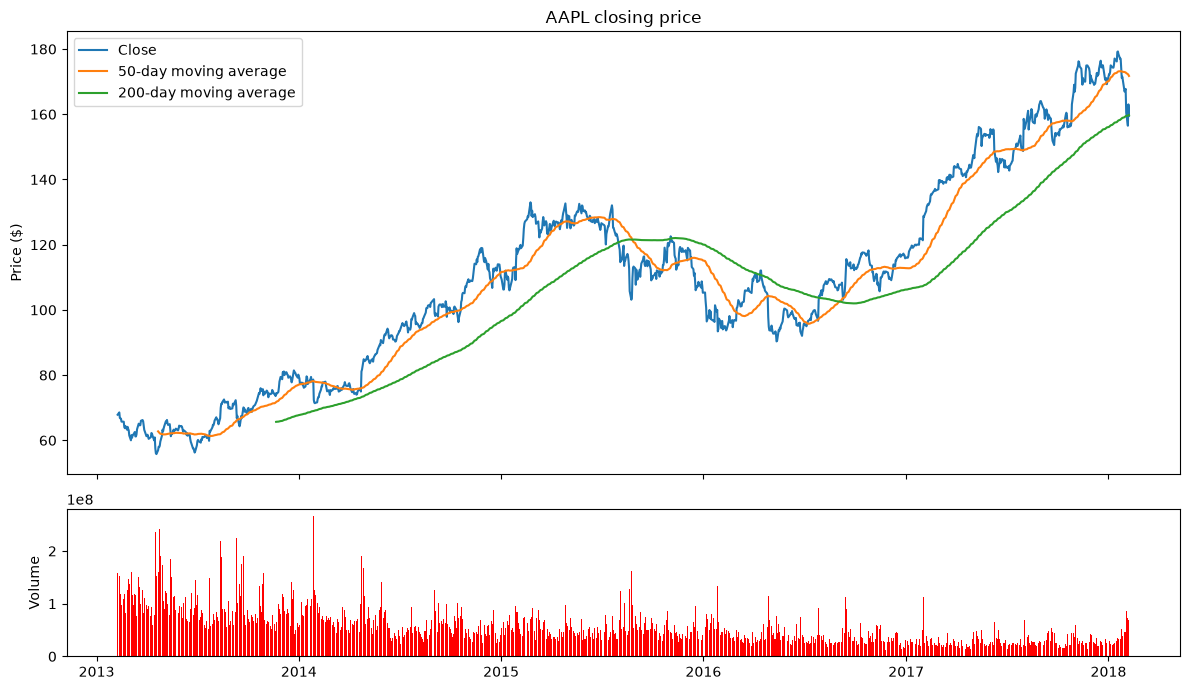

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})

axes[0].plot(dataset.index, dataset['close'], label='Close')
axes[0].plot(dataset.index, dataset['close'].rolling(50).mean(), label='50-day moving average')
axes[0].plot(dataset.index, dataset['close'].rolling(200).mean(), label='200-day moving average')
axes[0].set_ylabel('Price ($)')
axes[0].set_title(f'{TICKER} closing price')
axes[0].legend()

axes[1].bar(dataset.index, dataset['volume'], width=1.5, color='red')
axes[1].set_ylabel('Volume')
plt.tight_layout()
plt.show()

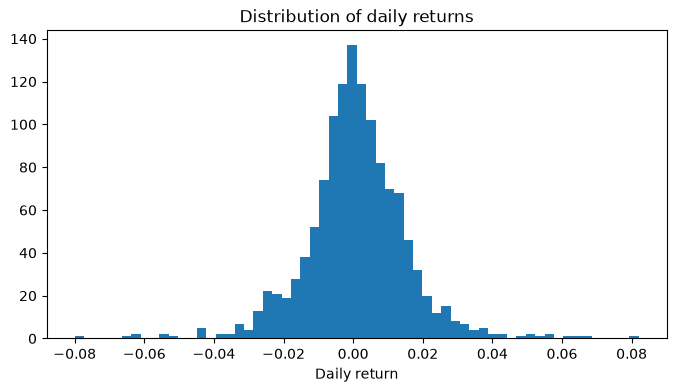

Mean daily return : 0.00079
Daily volatility  : 0.0


In [55]:
daily_return = dataset['close'].pct_change()

plt.figure(figsize=(8, 4))
plt.hist(daily_return.dropna(), bins=60)
plt.title('Distribution of daily returns')
plt.xlabel('Daily return')
plt.show()

print("Mean daily return :", round(daily_return.mean(), 5))
print("Daily volatility  :", round(daily_return.std(), 1))

## 3. Feature engineering

Each row describes **day t** using only information known at the close of day t. The targets refer to **day t+1**:

* `target_close`: tomorrow's closing price (regression)
* `target_up`: 1 if tomorrow's close is higher than today's, else 0 (classification)

In [57]:
df = dataset.copy()

# Lagged closing prices
for lag in range(1, 6):
    df[f'close_lag_{lag}'] = df['close'].shift(lag)

# Moving averages and the distance of the price from them
for w in [5, 10, 20]:
    df[f'ma_{w}'] = df['close'].rolling(w).mean()
df['close_vs_ma_20'] = df['close'] / df['ma_20'] - 1

# Returns, volatility, intraday range, volume change
df['return_1d'] = df['close'].pct_change()
df['return_5d'] = df['close'].pct_change(5)
df['volatility_10'] = df['return_1d'].rolling(10).std()
df['high_low_range'] = (df['high'] - df['low']) / df['close']
df['volume_change'] = df['volume'].pct_change()

# Targets (tomorrow)
df['target_close'] = df['close'].shift(-1)
df['target_up'] = (df['target_close'] > df['close']).astype(int)

df = df.dropna()
print(df.shape)
print(df.head())

(1239, 21)
               open     high      low    close     volume  close_lag_1  \
date                                                                     
2013-03-08  61.3999  62.2042  61.2299  61.6742   97854442      61.5117   
2013-03-11  61.3928  62.7157  60.7342  62.5528  118272126      61.6742   
2013-03-12  62.2285  62.6971  61.0814  61.2042  116268341      62.5528   
2013-03-13  61.2071  62.0714  60.7657  61.1928  101369051      61.2042   
2013-03-14  61.8328  62.0914  61.4928  61.7857   75834906      61.1928   

            close_lag_2  close_lag_3  close_lag_4  close_lag_5  ...     ma_10  \
date                                                            ...             
2013-03-08      60.8088      61.5919      60.0071      61.4957  ...  62.10520   
2013-03-11      61.5117      60.8088      61.5919      60.0071  ...  62.03477   
2013-03-12      61.6742      61.5117      60.8088      61.5919  ...  61.74134   
2013-03-13      62.5528      61.6742      61.5117      60.8088  .

## 4. Train / test split

Stock prices are a **time series**, so the split must be chronological: train on the past, test on the future.
A random split (`train_test_split(..., shuffle=True)`) would let the model see days that come after the test days, which inflates the scores.

The scaler is fitted on the training set only and then applied to the test set.

In [12]:
features = [c for c in df.columns if c not in ['target_close', 'target_up']]

x = df[features]
y_reg = df['target_close']
y_clf = df['target_up']

split = int(len(df) * 0.8)
x_train, x_test = x.iloc[:split], x.iloc[split:]
y_train, y_test = y_reg.iloc[:split], y_reg.iloc[split:]
yc_train, yc_test = y_clf.iloc[:split], y_clf.iloc[split:]

print("Train:", x_train.index.min().date(), "->", x_train.index.max().date(), x_train.shape)
print("Test :", x_test.index.min().date(), "->", x_test.index.max().date(), x_test.shape)

sc_x = StandardScaler()
x_train_scaled = sc_x.fit_transform(x_train)   # fit on train only
x_test_scaled = sc_x.transform(x_test)         # transform test with the same scaler

Train: 2013-03-08 -> 2017-02-10 (991, 19)
Test : 2017-02-13 -> 2018-02-06 (248, 19)


## 5. Regression: predicting tomorrow's closing price

The **naive baseline** says "tomorrow's price = today's price". Any useful model has to beat it.

In [14]:
def evaluate(name, y_true, y_pred):
    return {
        'Model': name,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        'R2': r2_score(y_true, y_pred),
    }

results = []
predictions = {}

# Naive baseline
predictions['Naive (today = tomorrow)'] = x_test['close'].values

# Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(x_train_scaled, y_train)
predictions['Linear Regression'] = lin_reg.predict(x_test_scaled)

# KNN Regressor
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(x_train_scaled, y_train)
predictions['KNN Regressor'] = knn_reg.predict(x_test_scaled)

# Random Forest
rf_reg = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_reg.fit(x_train_scaled, y_train)
predictions['Random Forest'] = rf_reg.predict(x_test_scaled)

for name, pred in predictions.items():
    results.append(evaluate(name, y_test.values, pred))

results_df = pd.DataFrame(results).set_index('Model').round(3)
print(results_df)

                             MAE    RMSE  MAPE (%)     R2
Model                                                    
Naive (today = tomorrow)   1.307   1.892     0.832  0.975
Linear Regression          1.333   1.902     0.848  0.975
KNN Regressor             26.201  28.778    16.311 -4.728
Random Forest             26.307  28.940    16.369 -4.793


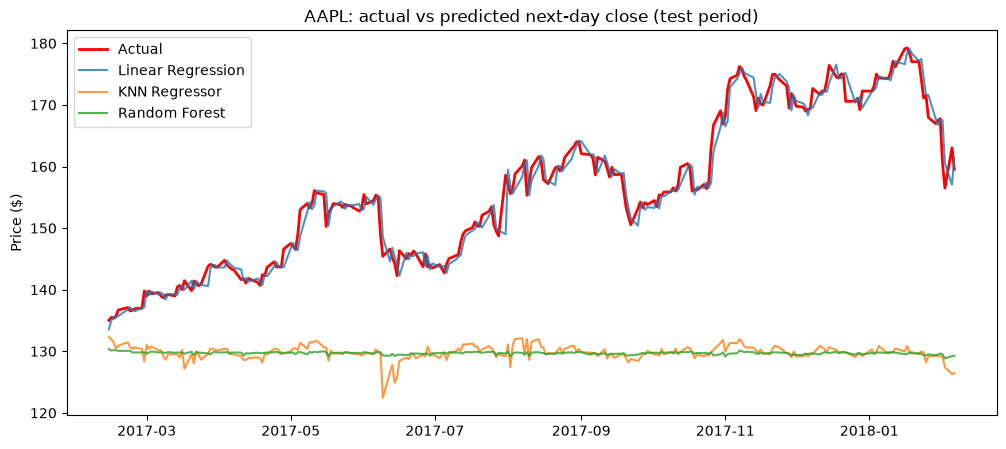

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label='Actual', color='red', linewidth=2)
for name in ['Linear Regression', 'KNN Regressor', 'Random Forest']:
    plt.plot(y_test.index, predictions[name], label=name, alpha=0.8)
plt.title(f'{TICKER}: actual vs predicted next-day close (test period)')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

**Why KNN and Random Forest look bad here:** tree and neighbour models can only predict values close to what they saw in training.
In the test period AAPL trades above its training range, so they get stuck at the highest prices they know.
Linear Regression can extrapolate, which is why it tracks the price, but its error is the same as the naive baseline (it essentially learns "tomorrow ≈ today").

A common fix is to predict the **return** (percentage change) instead of the price, because returns stay in a similar range over time:

In [16]:
# Predict tomorrow's return, then convert it back to a price
r_train = y_train / x_train['close'] - 1
r_test = y_test / x_test['close'] - 1

rf_ret = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_ret.fit(x_train_scaled, r_train)
pred_price_rf_ret = x_test['close'].values * (1 + rf_ret.predict(x_test_scaled))

knn_ret = KNeighborsRegressor(n_neighbors=25)
knn_ret.fit(x_train_scaled, r_train)
pred_price_knn_ret = x_test['close'].values * (1 + knn_ret.predict(x_test_scaled))

extra = pd.DataFrame([
    evaluate('Random Forest (on returns)', y_test.values, pred_price_rf_ret),
    evaluate('KNN (on returns)', y_test.values, pred_price_knn_ret),
]).set_index('Model').round(3)

print(pd.concat([results_df, extra]))

                               MAE    RMSE  MAPE (%)     R2
Model                                                      
Naive (today = tomorrow)     1.307   1.892     0.832  0.975
Linear Regression            1.333   1.902     0.848  0.975
KNN Regressor               26.201  28.778    16.311 -4.728
Random Forest               26.307  28.940    16.369 -4.793
Random Forest (on returns)   1.735   2.248     1.106  0.965
KNN (on returns)             1.372   1.948     0.871  0.974


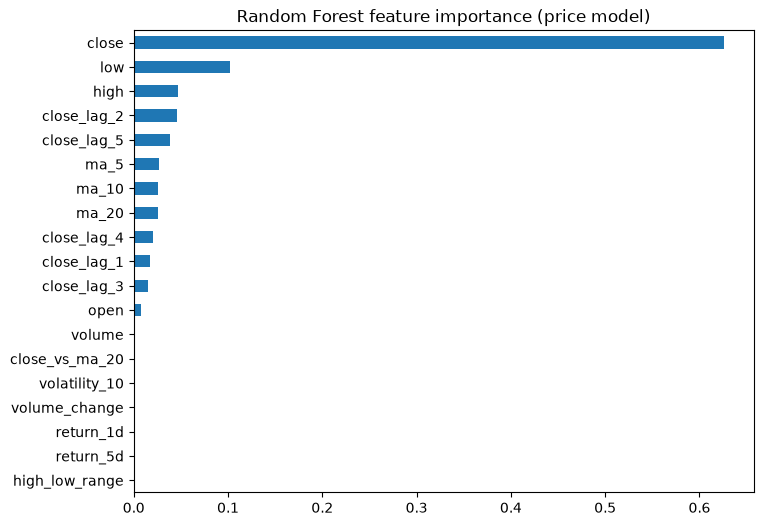

In [17]:
importances = pd.Series(rf_reg.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 6))
importances.plot(kind='barh')
plt.title('Random Forest feature importance (price model)')
plt.show()

## 6. Classification: will the price go up tomorrow?

For a trader the **direction** often matters more than the exact price.
Baseline: always predict the most frequent class of the training set.

Share of 'up' days in test set : 0.524
Baseline accuracy (always 1 ): 0.524
Best k on validation: 51


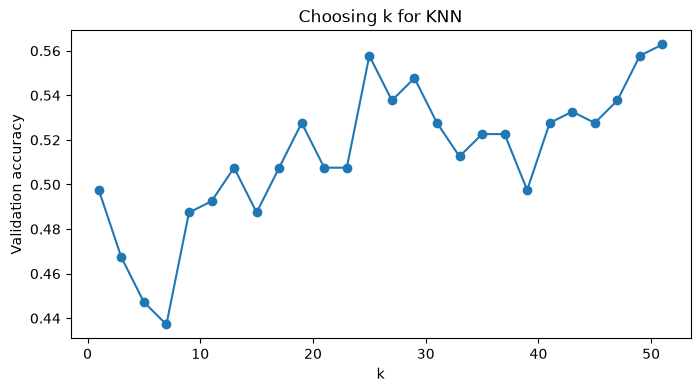

In [18]:
majority_class = yc_train.mode()[0]
baseline_acc = accuracy_score(yc_test, np.full(len(yc_test), majority_class))
print("Share of 'up' days in test set :", round(yc_test.mean(), 3))
print("Baseline accuracy (always", majority_class, "):", round(baseline_acc, 3))

# Choose k for KNN using the last 20% of the training period as validation
val_split = int(len(x_train_scaled) * 0.8)
k_scores = {}
for k in range(1, 52, 2):
    m = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    m.fit(x_train_scaled[:val_split], yc_train.iloc[:val_split])
    k_scores[k] = accuracy_score(yc_train.iloc[val_split:], m.predict(x_train_scaled[val_split:]))

best_k = max(k_scores, key=k_scores.get)
print("Best k on validation:", best_k)

plt.figure(figsize=(8, 4))
plt.plot(list(k_scores.keys()), list(k_scores.values()), marker='o')
plt.xlabel('k')
plt.ylabel('Validation accuracy')
plt.title('Choosing k for KNN')
plt.show()

In [19]:
knn_clf = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_clf.fit(x_train_scaled, yc_train)
yc_pred_knn = knn_clf.predict(x_test_scaled)

log_clf = LogisticRegression(max_iter=1000)
log_clf.fit(x_train_scaled, yc_train)
yc_pred_log = log_clf.predict(x_test_scaled)

print("KNN accuracy                :", round(accuracy_score(yc_test, yc_pred_knn), 3))
print("Logistic Regression accuracy:", round(accuracy_score(yc_test, yc_pred_log), 3))
print("Baseline accuracy           :", round(baseline_acc, 3))
print()
print(classification_report(yc_test, yc_pred_log, target_names=['Down', 'Up'], zero_division=0))
print("Confusion matrix (Logistic Regression):")
print(confusion_matrix(yc_test, yc_pred_log))

KNN accuracy                : 0.484
Logistic Regression accuracy: 0.484
Baseline accuracy           : 0.524

              precision    recall  f1-score   support

        Down       0.48      0.97      0.64       118
          Up       0.62      0.04      0.07       130

    accuracy                           0.48       248
   macro avg       0.55      0.51      0.36       248
weighted avg       0.56      0.48      0.34       248

Confusion matrix (Logistic Regression):
[[115   3]
 [125   5]]


## 7. Prediction for a new day

Same idea as the `predictDiabetic` function: build the feature row for the last available day, scale it with the **already fitted** scaler (`transform`, not `fit_transform`), and predict.

In [21]:
def predictNextDay(history):
    """history: DataFrame with columns open, high, low, close, volume (at least 25 rows)."""
    h = history.copy()
    for lag in range(1, 6):
        h[f'close_lag_{lag}'] = h['close'].shift(lag)
    for w in [5, 10, 20]:
        h[f'ma_{w}'] = h['close'].rolling(w).mean()
    h['close_vs_ma_20'] = h['close'] / h['ma_20'] - 1
    h['return_1d'] = h['close'].pct_change()
    h['return_5d'] = h['close'].pct_change(5)
    h['volatility_10'] = h['return_1d'].rolling(10).std()
    h['high_low_range'] = (h['high'] - h['low']) / h['close']
    h['volume_change'] = h['volume'].pct_change()

    last_row = h[features].iloc[[-1]]
    last_scaled = sc_x.transform(last_row)

    price = lin_reg.predict(last_scaled)[0]
    prob_up = log_clf.predict_proba(last_scaled)[0][1]

    print("Last date        :", h.index[-1].date())
    print("Last close       :", round(h['close'].iloc[-1], 2))
    print("Predicted close  :", round(price, 2))
    print("Probability 'up' :", round(prob_up, 3))
    return "Up" if prob_up >= 0.5 else "Down"

print(predictNextDay(dataset))

Last date        : 2018-02-07
Last close       : 159.54
Predicted close  : 159.51
Probability 'up' : 0.447
Down


## 8. Conclusion

* **Price prediction:** Linear Regression follows the price closely (R² ≈ 0.97), but so does the naive "tomorrow = today" rule, and no model beats it on MAE. A high R² on prices is misleading because tomorrow's price is always close to today's. KNN and Random Forest on raw prices fail when prices leave the training range; predicting returns fixes that.
* **Direction prediction:** accuracy (about 48%) is no better than always predicting "up" (52%), so roughly a coin flip. Daily stock moves are mostly noise, so price history alone gives limited predictive power, which is consistent with the efficient market hypothesis.
* **Good practice applied:** chronological split, scaler fitted on train only, comparison with a naive baseline.

**Possible improvements:** walk-forward (rolling) validation with `TimeSeriesSplit`, an LSTM network on sequences of prices, more indicators (RSI, MACD, Bollinger bands), and external data (market index, news sentiment).